In [1]:
import numpy as np
import scipy.signal as signal
import soundfile as sf
from scipy.io import wavfile
import random
import matplotlib.pyplot as plt

# Reproducibility: set a global seed and create a Generator
# Change SEED to any integer to reproduce different runs
SEED = 1
np.random.seed(SEED)  # seeds legacy RandomState functions (e.g. np.random.randn)
rng = np.random.default_rng(SEED)  # preferred Generator for new code
random.seed(SEED)


In [ ]:
soundcard_fs = 48000  # Sampling rate of sound card these are generated for

In [3]:
def generate_filtered_pink_pulse(duration_ms=2000, fs=48000, band=(8000, 16000), amplitude=0.25, rng=None):
    """
    Generate filtered pink noise pulse at final output amplitude.
    Accepts an optional `rng` (numpy Generator). If `rng` is None the global `rng` is used.
    No additional scaling needed in Bonsai.
    """
    # Use provided RNG or fall back to global `rng` or new Generator
    if rng is None:
        try:
            rng = globals().get('rng', None)
            if rng is None:
                rng = np.random.default_rng()
        except Exception:
            rng = np.random.default_rng()

    # Duration in samples
    duration = int((duration_ms / 1000) * fs)
    
    # Generate pink noise using Voss method approximation
    def pink_noise(n_samples):
        white = rng.standard_normal(n_samples)
        b, a = signal.butter(1, 0.01, btype='low')  # crude pink approximation
        return signal.lfilter(b, a, white)

    noise = pink_noise(duration * 2)  # generate more to allow for filtering edge artifacts

    # Bandpass filter design
    nyq = fs / 2
    b, a = signal.butter(4, [band[0]/nyq, band[1]/nyq], btype='band')
    filtered = signal.lfilter(b, a, noise)

    # Truncate to exact duration
    filtered = filtered[:duration]

    # Apply 16 ms sinusoidal ramp
    ramp_samples = int(0.016 * fs)
    ramp = np.sin(np.linspace(0, np.pi/2, ramp_samples))**2  # raised cosine ramp
    envelope = np.ones_like(filtered)
    envelope[:ramp_samples] *= ramp
    envelope[-ramp_samples:] *= ramp[::-1]
    shaped = filtered * envelope

    # Normalize and set to final amplitude (ready to use)
    shaped /= np.max(np.abs(shaped))  # normalize to 1.0
    shaped *= amplitude  # set final amplitude - no scaling needed in Bonsai

    return shaped, fs


In [ ]:
def generate_white_noise(duration_s=60, fs=48000, amplitude=0.1, rng=None):
    """
    Generate white noise at final output amplitude.
    Accepts an optional `rng` (numpy Generator). If `rng` is None the global `rng` is used.
    No additional scaling needed in Bonsai.
    """
    if rng is None:
        try:
            rng = globals().get('rng', None)
            if rng is None:
                rng = np.random.default_rng()
        except Exception:
            rng = np.random.default_rng()

    noise = rng.standard_normal(int(duration_s * fs))
    noise /= np.max(np.abs(noise))
    noise *= amplitude  # set final amplitude - no scaling needed in Bonsai
    return noise, fs



In [5]:
def generate_go_cue_wav(output_filename="go_cue.wav"):
    """
    Generate a WAV file with a 10 kHz pure tone for 0.1 seconds.
    
    Parameters:
    - output_filename: Name of the WAV file to create
    
    This generates the auditory Go cue as described in the paper:
    - Frequency: 10 kHz
    - Duration: 0.1 seconds
    """
    # Audio parameters
    frequency = 10000  # 10 kHz
    duration = 0.1     # 0.1 seconds
    sample_rate = 44100  # Standard audio sample rate
    amplitude = 0.9    # Volume (0.0 to 1.0) - using 0.9 for a strong signal
    
    # Generate time array
    t = np.linspace(0, duration, int(sample_rate * duration), False)
    
    # Generate tone (sine wave)
    tone = amplitude * np.sin(2 * np.pi * frequency * t)
    
    # Ensure the audio data is in the correct format for WAV files
    # Convert to 16-bit PCM
    tone_int16 = (tone * 32767).astype(np.int16)
    
    # Save as WAV file
    wavfile.write(output_filename, sample_rate, tone_int16)
    print(f"Go cue audio saved to {output_filename}")

# Generate the WAV file
if __name__ == "__main__":
    generate_go_cue_wav()


Go cue audio saved to go_cue.wav


In [6]:
def generate_8hz_pink_noise_train(total_duration_s=1.5, pulse_duration_ms=50, pulse_rate_hz=8, fs=44100, band=(8000,16000), amplitude=0.25, rng=None):
    """
    Generate a pulse train of filtered pink pulses at `rate_hz` (default 8 Hz).

    - `pulse_duration_ms`: duration of each pulse in milliseconds (default 50 ms)
    - `total_duration_s`: total length of the output signal in seconds
    - Pulses have 16 ms sinusoidal onset/offset ramps (applied by
      `generate_filtered_pink_pulse`). Zeros are placed between pulses.

    Returns (signal, fs).
    """
    # Use provided RNG or fall back to global/default
    if rng is None:
        try:
            rng = globals().get('rng', None)
            if rng is None:
                rng = np.random.default_rng()
        except Exception:
            rng = np.random.default_rng()

    period_s = 1.0 / pulse_rate_hz
    period_samples = int(round(period_s * fs))
    total_samples = int(round(total_duration_s * fs))

    out = np.zeros(total_samples)
    n_periods = int(np.floor(total_duration_s * pulse_rate_hz))

    for i in range(n_periods):
        # Generate individual random pulses (it applies its own 16 ms ramps)
        pulse, _ = generate_filtered_pink_pulse(duration_ms=pulse_duration_ms, fs=fs, band=band, amplitude=amplitude, rng=rng)
        pulse_samples = len(pulse)

        start = i * period_samples
        end = start + pulse_samples
        if start >= total_samples:
            break
        if end > total_samples:
            end = total_samples
            out[start:end] = pulse[: end - start]
        else:
            out[start:end] = pulse

    return out, fs


In [ ]:
if __name__ == "__main__":
    # Generate filtered pink pulse (ready to use - no scaling needed)
    if 0:  # Replaced by pink_noise_train now
        pink_pulse, fs_pulse = generate_filtered_pink_pulse(
            duration_ms=1500, 
            band=(8000,16000),
            fs=soundcard_fs, 
            amplitude=0.25  # Final amplitude for stimulus presentation
        )
        sf.write("filtered_pink_pulse.wav", pink_pulse, fs_pulse)
        print("Filtered pink pulse saved")
    #
    
    # Generate background white noise (ready to use - no scaling needed)
    bg_noise, fs_noise = generate_white_noise(
        duration_s=7200,
        fs=soundcard_fs,
        amplitude=0.1  # Final amplitude for background noise
    )
    sf.write("background_white_noise.wav", bg_noise, fs_noise)
    print("Background white noise saved")
    
    # Generate filtered pink pulse (ready to use - no scaling needed)
    pink_pulse_train, fs_pulse = generate_8hz_pink_noise_train(
        total_duration_s=1.5,
        pulse_duration_ms=50,
        pulse_rate_hz=8,
        fs=soundcard_fs,
        band=(8000,16000),
        amplitude=0.25  # Final amplitude for stimulus presentation
    )
    sf.write("filtered_pink_pulse_train.wav", pink_pulse_train, fs_pulse)
    print("Filtered pink pulse train saved")
    

Filtered pink pulse saved
Background white noise saved
Filtered pink pulse train saved


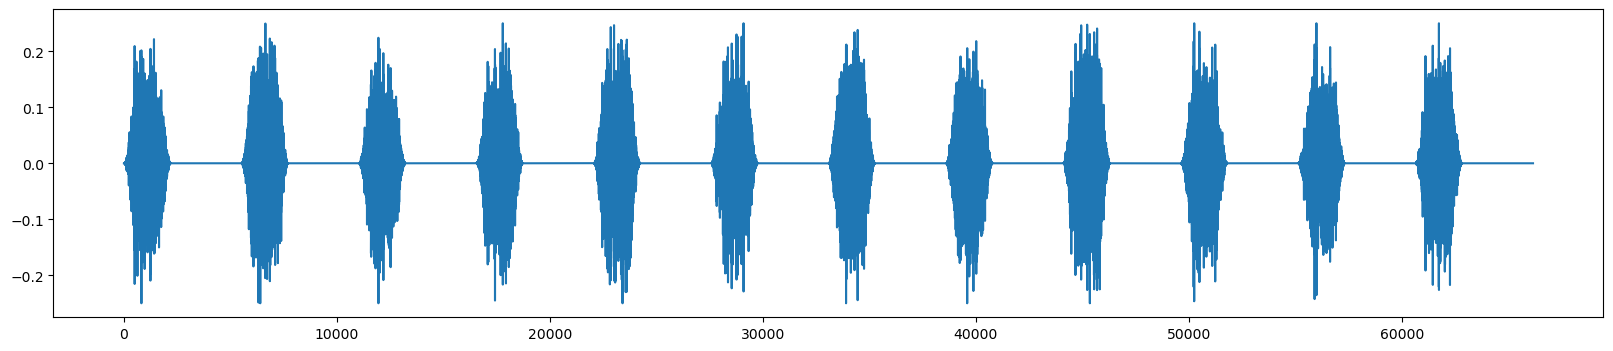

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(20, 4))
plt.plot(pink_pulse_train)
plt.show()